<a href="https://colab.research.google.com/github/CienciaDatosUdea/005_CCA_Estudiantes/blob/main/Laboratorios/14_Lab_PrediccionesML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratorio 14 — Predicciones sobre grafos con ML tradicional
## Cristal y líquido en un coloide real: nodos, relaciones y grafos

**Computación Científica Avanzada · Unidad 4, sesión 2**

En una muestra coloidal coexisten un cristal y un líquido. Con solo las posiciones medidas de las partículas, convertidas en un **grafo de vecinos**, vamos a responder una pregunta de cada una de las tres tareas de Hamilton :

| Parte | Tarea | Pregunta |
|---|---|---|
| A | Clasificación de nodos | ¿Es cristalina esta partícula? |
| B | Predicción de relaciones | ¿Qué partículas serán vecinas dentro de 100 s? |
| C | Clasificación de grafos | ¿Qué capas de la muestra son cristal y dónde está la interfaz? |

En parejas se resuelven las preguntas, se entregan los laboratorios de manera individual por el git de la clase y en parejas se hace una exposición de las soluciones en clase. Las celdas con `# COMPLETAR` son las que deben escribir; hay una celda de verificación con `assert`. Al final del lab hay una celda para declarar las asistencia de la IA.

# Parte 0 — Preparación

### Coloides
Un coloide es una suspensión de partículas sólidas, de unos cientos de nanómetros a unos micrones, en un líquido. Las partículas se mueven por movimiento browniano y, si la repulsión entre ellas es de corto alcance, se comportan aproximadamente como esferas duras. Para esferas duras ideales, la única variable termodinámica es la fracción de volumen $\phi$, la fracción del espacio ocupada por partículas:

- para $\phi<0{,}494$ el sistema es líquido: partículas desordenadas que difunden;
- para $\phi>0{,}545$ es cristal: las partículas se ordenan en una red compacta y vibran alrededor de sus sitios;
- entre ambos valores, cristal y líquido coexisten, separados por una interfaz.

En esferas duras ideales la transición la produce solo la entropía: a alta densidad, ordenarse deja a cada partícula más espacio para moverse. Por la misma razón la interfaz cuesta energía libre: allí las partículas no se empaquetan bien ni como cristal ni como líquido, y eso da una tensión superficial de origen entrópico. Como las partículas son mil veces más grandes que un átomo y mucho más lentas, los coloides permiten estudiar experimentalmente estas fases partícula por partícula.

Las partículas de este experimento tienen una ligera carga eléctrica, que desplaza las fronteras de fase: los autores miden la congelación en $\phi_\text{freeze}=0{,}43$ y la fusión en $\phi_\text{melt}=0{,}49$. Su cristal está formado por capas hexagonales compactas apiladas al azar, una mezcla de los apilamientos fcc y hcp.

- $\phi_\text{freeze}$ («congelación») es la fracción de volumen a la que el **líquido** empieza a cristalizar cuando se va comprimiendo la muestra. Por debajo de $\phi_\text{freeze}$ todo es líquido.
- $\phi_\text{melt}$ («fusión») es la fracción de volumen a la que el **cristal** empieza a fundirse cuando se va diluyendo. Por encima de $\phi_\text{melt}$ todo es cristal.
- Entre las dos, el sistema se separa en dos fases que **coexisten**: un líquido con $\phi=\phi_\text{freeze}$ y un cristal con $\phi=\phi_\text{melt}$. Eso es lo que hay en la muestra del experimento, con la interfaz entre ambas.

### El experimento
Usamos los datos de Hernández-Guzmán y Weeks, PNAS 106, 15198 (2009), publicados en el [sitio del grupo de Eric Weeks](https://faculty.college.emory.edu/sites/weeks/data/jessy.html). Las partículas son de PMMA (polimetilmetacrilato), con diámetro $d=2{,}30\pm0{,}02$ µm y una polidispersidad de un 5 %, teñidas con un colorante fluorescente y suspendidas en una mezcla de bromuro de ciclohexilo y decalina. La mezcla iguala casi la densidad y el índice de refracción de las partículas, pero los autores añadieron a propósito un poco más de decalina, de modo que las partículas son ligeramente más densas que el líquido. La muestra, en una celda de $0{,}4\times3\times30$ mm³ guardada en vertical, se dejó equilibrar más de un mes. La gravedad produce así un gradiente de concentración: abajo, donde las partículas se acumulan, hay cristal; arriba, líquido; y en medio una interfaz en equilibrio, que ni crece ni se funde durante la medida.

Un microscopio confocal toma un volumen de $20\times55\times60$ µm³ cada 25 s durante 3750 s (algo más de una hora), con una resolución de 0,05–0,1 µm en la posición de cada partícula. Un programa de seguimiento localiza cada partícula y la identifica de un instante al siguiente.

Orientación de los ejes. En el archivo, el eje $x$ (unos 58 µm) es la dirección de la gravedad, que el artículo llama $z$: el cristal está a $x$ pequeño (abajo) y el líquido a $x$ grande (arriba). El eje $z$ del archivo (unos 20 µm) es el eje óptico del microscopio. La interfaz no es exactamente perpendicular a $x$: está inclinada unos 15°, y los autores rotan los datos para alinearla. Además se ondula por ondas capilares, que mueven su posición hasta unos 4 diámetros de pico a pico. Nosotros trabajaremos con capas perpendiculares a $x$ sin rotar, así que nuestros perfiles saldrán algo más anchos que los del artículo.

### El archivo
Cada fila es una partícula en un instante:

| columna | significado |
|---|---|
| `x, y, z` | posición en µm |
| `N_o` | número de vecinos **ordenados** (ver abajo). Los autores llaman cristalina a una partícula si $N_o\ge8$, es decir, $N_o>7$ |
| `c` | coordinación: número de vecinos a menos de $1{,}41\,d$, el primer mínimo de la función de distribución radial $g(r)$ del líquido |
| `t` | instante, de 0 a 149 (cada paso son 25 s) |
| `ID` | identificador de la partícula, el mismo en todos los instantes |

`N_o` resume el **orden orientacional**: en un cristal los enlaces con los vecinos apuntan en direcciones fijas, en un líquido no. Para medirlo, los autores calculan para cada partícula $i$ el **parámetro de orden de enlaces** de Steinhardt, un vector de $2l+1=13$ componentes complejas
$$
\hat q_{6m}(i)\propto\sum_{j\in\mathcal N(i)}Y_{6m}(\hat{\mathbf r}_{ij}),\qquad m=-6,\dots,6,
$$
normalizado a longitud 1, donde $\hat{\mathbf r}_{ij}$ es la dirección hacia el vecino $j$ y $Y_{6m}$ son armónicos esféricos. Dos vecinos son ordenados si $\sum_m\hat q_{6m}(i)\,\hat q_{6m}^*(j)>0{,}5$, es decir, si sus entornos apuntan en direcciones parecidas. $N_o$ será la etiqueta experimental de las partes A y C; los rasgos saldrán únicamente del grafo.

### El grafo
Unimos dos partículas si sus centros están a menos de $r_c=1{,}41\,d=3{,}24$ µm, el mismo criterio de vecinos del artículo y de la columna `c`. El grafo sabe cuántos vecinos tiene cada partícula y si esos vecinos se conocen entre sí, pero no en qué direcciones están. Tenga presente esa diferencia durante todo el ejercicio.

# Parte 1 — Datos y grafo

## 1.1 Librerías y descarga
El archivo pesa 6,3 MB comprimido. Si la descarga falla, bájelo a mano desde el sitio del grupo y súbalo a Colab con el icono de carpeta del panel izquierdo.

In [1]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from pathlib import Path
from urllib.request import urlretrieve
from zipfile import ZipFile
from scipy.spatial import cKDTree
from scipy.sparse import triu
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

In [2]:
if not Path("hp02s5bb.txt").exists():
    if not Path("pnas09.zip").exists():
        urlretrieve("https://faculty.college.emory.edu/sites/weeks/data/pnas09.zip", "pnas09.zip")
    ZipFile("pnas09.zip").extractall()

datos = np.loadtxt("hp02s5bb.txt")
t = datos[:, 5].astype(int)
print(datos.shape[0], "filas,", np.unique(t).size, "instantes,", np.unique(datos[:, 6]).size, "partículas distintas")

726988 filas, 150 instantes, 27661 partículas distintas


In [3]:
d = 2.30            # diámetro de las partículas, µm
rc = 1.41 * d       # radio de corte, µm

def instante(k):
    """Devuelve (X, N_o, c, ID) de las partículas presentes en el instante k.

    X: (n,3) posiciones x,y,z en µm; N_o: (n,) vecinos ordenados;
    c: (n,) coordinación; ID: (n,) identificadores enteros.
    """
    f = datos[t == k]
    return f[:, :3], f[:, 3], f[:, 4], f[:, 6].astype(int)

X, N_o, c, ID = instante(0)
X

array([[56.3 , 22.03,  7.57],
       [56.63,  1.76,  0.74],
       [49.79, 21.23,  2.2 ],
       ...,
       [28.3 , 30.63,  0.31],
       [ 0.19, 40.94, 15.88],
       [14.05, 17.65, 14.27]], shape=(4691, 3))

Una lámina delgada de la muestra ($z$ entre 8 y 10 µm), con las partículas cristalinas según los autores.

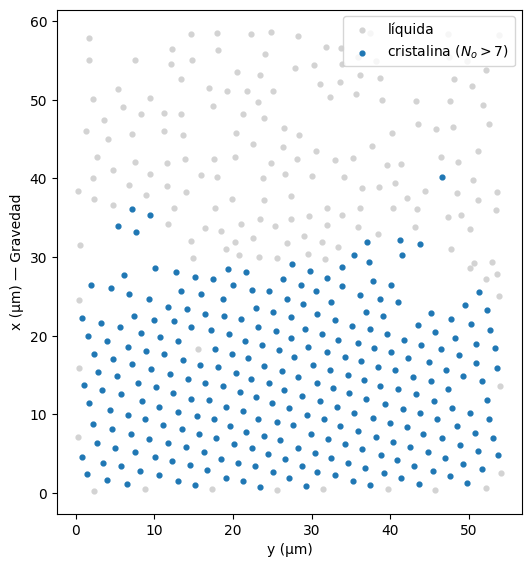

In [4]:
lamina = (X[:, 2] > 8) & (X[:, 2] < 10)
cristalina = N_o > 7
plt.figure(figsize=(6, 7))

# y en el eje horizontal, x en el eje vertical
plt.scatter(X[lamina & ~cristalina, 1], X[lamina & ~cristalina, 0], s=12, color="lightgray", label="líquida")
plt.scatter(X[lamina & cristalina, 1], X[lamina & cristalina, 0], s=12, color="tab:blue", label="cristalina ($N_o>7$)")

plt.xlabel("y (µm)")
plt.ylabel("x (µm) — Gravedad")
plt.gca().set_aspect("equal")
plt.legend(loc="upper right")
plt.show()

## Tarea 1. Grafo de vecinos
Complete `grafo_de_vecinos`. Con unas 4800 partículas conviene un **árbol k-d** (`scipy.spatial.cKDTree`): su método `query_pairs(r)` devuelve los pares $(i, j)$, con $i<j$, a distancia menor que $r_c$, sin calcular todas las distancias.

*Sugerencia para el asistente de IA:* «¿Cómo construyo con `scipy.spatial.cKDTree` y NetworkX un grafo cuyos nodos sean las filas 0..n-1 de un arreglo X y cuyas aristas unan los pares a menos de r?». Asegúrese de que el grafo incluya también las partículas sin vecinos.

In [5]:
def grafo_de_vecinos(X, rc):
    """Grafo con un nodo por fila de X (nodos 0, ..., n-1) y una arista entre
    las partículas cuyos centros están a menos de rc."""

    X = np.asarray(X)
    n = len(X)
    tree = cKDTree(X)  # Construye el árbol k-d para búsqueda espacial rápida
    pares = tree.query_pairs(rc, output_type="ndarray") # Pares (i, j) con i < j y distancia <= r_c, como arreglo (m, 2)

    G = nx.Graph()
    G.add_nodes_from(range(n))   # incluye nodos sin vecinos
    G.add_edges_from(pares)      # cada fila es una arista
    return G

In [6]:
# Verificación de la tarea 1
G = grafo_de_vecinos(X, rc)
grado = np.array([G.degree(u) for u in range(len(X))])
assert G.number_of_nodes() == len(X)
coincide = np.mean(grado == c)
assert coincide > 0.95, f"El grado debería coincidir con la columna c en casi todas las partículas ({coincide:.2f})"
print(f"Tarea 1 correcta: {G.number_of_edges()} aristas; el grado coincide con la coordinación de los autores en el {100 * coincide:.0f} % de las partículas")

Tarea 1 correcta: 22963 aristas; el grado coincide con la coordinación de los autores en el 98 % de las partículas


### Ver el grafo
Un grafo de 4800 nodos en 3D es ilegible. La función `dibujar` muestra solo una **ventana**: las partículas dentro de una caja, con las aristas entre ellas, proyectadas sobre dos ejes. La usaremos en todo el cuaderno.

In [7]:
def ventana(X, x=(0, 60), y=(0, 60), z=(0, 25)):
    """Índices de las partículas dentro de la caja dada (en µm)."""
    m = ((X[:, 0] >= x[0]) & (X[:, 0] < x[1]) & (X[:, 1] >= y[0]) & (X[:, 1] < y[1])
         & (X[:, 2] >= z[0]) & (X[:, 2] < z[1]))
    return np.where(m)[0]

def dibujar(G, X, nodos, colores="tab:blue", ejes=(0, 1), ax=None, **opciones):
    """Dibuja el subgrafo de los nodos dados, proyectado sobre los ejes elegidos (0 = x, 1 = y, 2 = z)."""
    ax = ax or plt.gca()
    pos = {u: X[u, list(ejes)] for u in nodos}
    nx.draw_networkx_edges(G.subgraph(nodos), pos, ax=ax, edge_color="0.75", width=0.8)
    nx.draw_networkx_nodes(G.subgraph(nodos), pos, nodelist=list(nodos), node_color=colores,
                           node_size=opciones.pop("node_size", 40), ax=ax, **opciones)
    ax.set_xlabel("xyz"[ejes[0]] + " (µm)"); ax.set_ylabel("xyz"[ejes[1]] + " (µm)")
    ax.set_aspect("equal"); ax.tick_params(left=True, bottom=True, labelleft=True, labelbottom=True)

Una ventana que cruza la interfaz, coloreada por el grado. A la izquierda se ve la red del cristal, con nodos de grado alto; a la derecha, el líquido, más ralo e irregular.

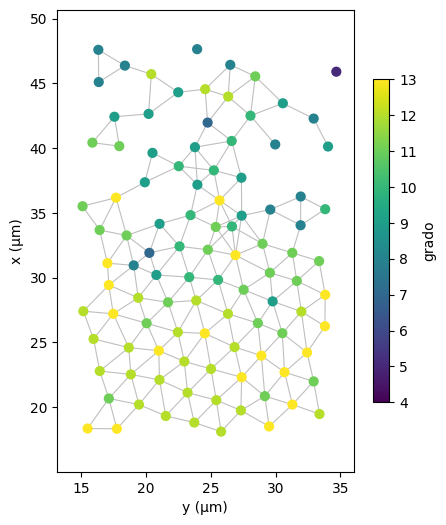

In [8]:
plt.figure(figsize=(5, 6))

zona_interfaz = ventana(X, x=(18, 48), y=(15, 35), z=(8, 10.5))

dibujar(G, X, zona_interfaz, colores=grado[zona_interfaz], cmap="viridis", vmin=4, vmax=13, ejes=(1, 0))

plt.colorbar(plt.gca().collections[-1], label="grado", shrink=0.7)
plt.show()

**Discutan**: ¿Por qué casi todos los nodos tienen menos aristas dibujadas que su grado? ¿Dónde están los vecinos que faltan? Cuidado: aquí la dirección perpendicular al dibujo es $z$, el eje óptico del microscopio, no la dirección de la gravedad, que es $x$.

Los nodos tienen menos aristas dibujadas que su grado porque el dibujo es una proyección 2D de un grafo 3D. Las aristas hacia vecinos en la dirección z  no se ven. Los vecinos que faltan están en la dirección perpendicular al dibujo  (eje óptico), y en los bordes de la ventana (fuera de la caja).

# Parte A — Clasificación de nodos: ¿es cristalina esta partícula?

Los autores clasificaron cada partícula con el orden orientacional ($N_o\ge8$). Suponga que solo conoce esa etiqueta para el **30 % de las partículas**, elegidas al azar, y quiere predecir la del resto a partir del grafo. Note que los nodos no son independientes: una partícula cristalina suele tener vecinos cristalinos, y la agregación de vecindario aprovecha esa correlación.

## Tarea 2. Rasgos de nodo
Complete `rasgos_de_nodo`. Debe devolver una matriz $F$ de forma $(n, 5)$ con estas columnas, en este orden:

| columna | rasgo | definición |
|---|---|---|
| 0 | grado | $d_u=\sum_vA[u,v]$ |
| 1 | agrupamiento | fracción de pares de vecinos de $u$ conectados |
| 2 | agregación de grado, ronda 1 | $\mathbf h^{(1)}=A\,\mathbf d$ |
| 3 | agregación de grado, ronda 2 | $\mathbf h^{(2)}=A\,\mathbf h^{(1)}$ |
| 4 | agrupamiento medio de los vecinos | $(A\,\mathbf c)_u/d_u$ (0 si $d_u=0$) |

Use una matriz de adyacencia **dispersa**, `nx.to_scipy_sparse_array(G, nodelist=range(n), format="csr")`: la densa tendría 23 millones de entradas.



In [9]:
nombres_nodo = ["grado", "agrupamiento", "h1", "h2", "agrupamiento vecinos"]

def rasgos_de_nodo(G):

    n = G.number_of_nodes()

    # Matriz de adyacencia dispersa
    A = nx.to_scipy_sparse_array(G, nodelist=range(n), format="csr")

    # Grado de cada nodo
    d = np.asarray(A.sum(axis=1)).ravel()

    # Agrupamiento de cada nodo
    c_dict = nx.clustering(G)
    c = np.array([c_dict[u] for u in range(n)])

    # Agregación de grado: primera ronda
    h1 = A @ d

    # Agregación de grado: segunda ronda
    h2 = A @ h1

    # Agrupamiento medio de los vecinos
    suma_c = A @ c

    agrupamiento_vecinos = np.divide(
        suma_c,
        d,
        out=np.zeros(n, dtype=float),
        where=d != 0
    )

    # Construir matriz de características
    F = np.column_stack([
        d,
        c,
        h1,
        h2,
        agrupamiento_vecinos
    ])

    return F

In [10]:
# Verificación de la tarea 2
F = rasgos_de_nodo(G)
u = 100
assert F.shape == (len(X), 5)
assert np.allclose(F[:, 0], grado), "Revise el grado"
assert np.isclose(F[u, 1], nx.clustering(G, u)), "Revise el agrupamiento"
assert np.isclose(F[u, 2], sum(G.degree(v) for v in G[u])), "h1(u) es la suma de los grados de los vecinos"
assert np.isclose(F[u, 4], np.mean([nx.clustering(G, v) for v in G[u]])), "Revise el agrupamiento de los vecinos"
print("Tarea 2 correcta")

Tarea 2 correcta


## Tarea 3. Entrenar
Complete `entrenar`: debe devolver `make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))` ajustado a los datos. La misma función servirá en la parte C.



In [11]:
def entrenar(F_train, y_train):

    """Regresión logística, con los rasgos estandarizados, ajustada a (F_train, y_train)."""

    modelo = make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000)
    )

    modelo.fit(F_train, y_train)

    return modelo

##  Evaluación

En la siguiente celda se divide el dataset reservando un 30% de las partículas para entrenar el modelo y un 70% para evaluar las predicciones. Se comparan distintas combinaciones de variables del grafo midiendo la exactitud (accuracy) en dos zonas: sobre toda la muestra y enfocándose en la región de la interfaz ($27 < x < 36\,\mu\text{m}$). Todo el procedimiento se promedia a lo largo de 10 ejecuciones con semillas aleatorias para garantizar que los resultados sean estables y no dependan de una división afortunada.


In [12]:
y_nodo = cristalina.astype(int)
franja = (X[:, 0] > 27) & (X[:, 0] < 36)

combinaciones = {"solo grado": [0], "grado + agrupamiento": [0, 1], "todos (con agregación)": [0, 1, 2, 3, 4]}

base = max(y_nodo.mean(), 1 - y_nodo.mean())
base_franja = max(y_nodo[franja].mean(), 1 - y_nodo[franja].mean())

print(f"{'rasgos':<26} {'toda la muestra':>16} {'interfaz':>10}")
print(f"{'línea base':<26} {base:>16.3f} {base_franja:>10.3f}")

for nombre, cols in combinaciones.items():
    total, interfaz = [], []
    for semilla in range(10):
        tr, te = train_test_split(np.arange(len(X)), train_size=0.3, random_state=semilla, stratify=y_nodo)
        modelo = entrenar(F[tr][:, cols], y_nodo[tr])
        total.append(modelo.score(F[te][:, cols], y_nodo[te]))
        te_f = te[franja[te]]
        interfaz.append(modelo.score(F[te_f][:, cols], y_nodo[te_f]))
    print(f"{nombre:<26} {np.mean(total):>16.3f} {np.mean(interfaz):>10.3f}")

rasgos                      toda la muestra   interfaz
línea base                            0.562      0.531
solo grado                            0.772      0.577
grado + agrupamiento                  0.811      0.608
todos (con agregación)                0.891      0.684


### Ver los aciertos y los errores
Con el modelo de todos los rasgos (la última semilla), coloreamos la ventana de la interfaz por la etiqueta de los autores y marcamos con borde rojo las partículas mal clasificadas.

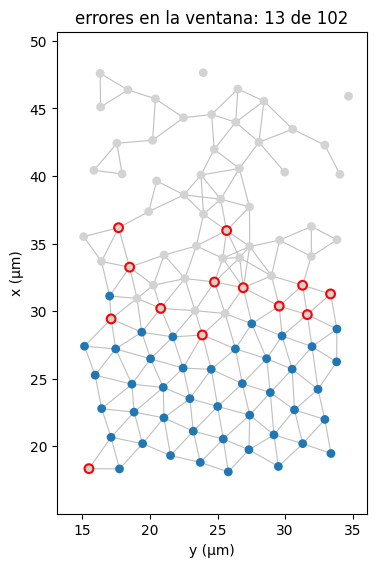

In [13]:
plt.figure(figsize=(4, 8))

prediccion = modelo.predict(F)
nodos = zona_interfaz
error = prediccion[nodos] != y_nodo[nodos]

# agregamos ejes=(1, 0) para proyectar y en horizontal y x en vertical
dibujar(G, X, nodos, colores=np.where(y_nodo[nodos] == 1, "tab:blue", "lightgray"),
        edgecolors=np.where(error, "red", "none"), linewidths=1.5, ejes=(1, 0))

plt.title(f"errores en la ventana: {error.sum()} de {len(nodos)}")
plt.show()

**Discutan:** ¿Dónde se concentran los errores? ¿Por qué la agregación mejora la exactitud? Piense en el campo receptivo: con $h^{(2)}$, cada partícula "ve" a sus vecinos a dos saltos. ¿Por qué la exactitud cae tanto en la interfaz?

## Respuestas  


**¿Dónde se concentran los errores?**

Los errores del modelo se concentran principalmente en la zona de la interfaz entre el cristal y el líquido (aproximadamente entre $x = 27\,\mu\text{m}$ y $x = 36\,\mu\text{m}$). Esto sucede porque allí las partículas cristalinas pierden vecinos de empaquetamiento, haciendo que su entorno se asemeje al del líquido. Además, el grafo de vecinos solo registra las conexiones entre partículas pero ignora los ángulos y direcciones orientacionales de los enlaces, los cuales son los que determinan la etiqueta real de cristalinidad ($N_o > 7$).

**¿Por qué la agregación mejora la exactitud?**

Si se tiene en cuenta solo el grado, una partícula ve únicamente su entorno inmediato. Con $h^{(1)}$ , ve a sus vecinos. Con $h^{(2)}$, ve a los vecinos de sus vecinos. En el cristal, no solo la partícula tiene grado alto sino que todo su entorno también está apretado. En el líquido, una partícula puede tener grado alto por una fluctuación momentánea, pero sus vecinos no están tan apretados. La agregación promedia el entorno, y eso le permite al modelo distinguir un patrón estructural estable (cristal) de una fluctuación aleatoria (líquido).


**¿Por qué la exactitud cae tanto en la interfaz?**

En la zona de coexistencia ($27 < x < 36\,\mu\text{m}$), las partículas que están justo en la frontera tienen parte de su vecindario dentro de la fase cristalina y la otra parte dentro del líquido. Esta transición rompe la homogeneidad, haciendo que los rasgos agregados de una partícula cristalina en el borde se parezcan mucho a los de una partícula líquida cercana. La etiqueta del artículo ($N_o > 7$) mide el orden orientacional (los ángulos en los que apuntan los enlaces). En la interfaz, el grado de empaquetamiento (conectividad del grafo) entre ambas fases es casi idéntico, pero sus simetrías angulares son totalmente distintas. Como el grafo solo registra aristas sin direcciones espaciales, el modelo pierde la capacidad de discriminar en esa zona intermedia.



# Parte B — Predicción de relaciones: ¿Quiénes serán vecinos?

En un líquido las partículas cambian de vecinos (la "jaula" que forman sus vecinos se reorganiza), y en un cristal casi no. Los autores midieron esta diferencia con el desplazamiento de las partículas: la movilidad sube del cristal al líquido a lo largo de unos $2{,}4\,d$, y en el líquido la difusión es unas 50 veces más lenta que en una suspensión diluida, porque la muestra es muy densa. Con el grafo en el instante $t$, ¿podemos predecir qué parejas de partículas serán vecinas en $t+\Delta t$, con $\Delta t=100$ s (4 instantes)?

**Candidatos :** Dos partículas a dos saltos en el grafo, es decir, no vecinas pero con al menos un vecino común, son las candidatas naturales a volverse vecinas. Para cada candidata usaremos como puntaje el número de vecinos comunes, que es $A^2[u,v]$.

**Etiqueta :** La pareja es positiva si en $t+\Delta t$ sus centros están a menos de $r_c$. Como las partículas se identifican por su `ID`, la celda siguiente construye las aristas del instante futuro expresadas con los índices del instante 0.

In [14]:
dt = 4                                              # instantes; 4 x 25 s = 100 s

X_f, _, _, ID_f = instante(dt)

indice = {i: j for j, i in enumerate(ID)}          # ID -> índice del nodo en el instante 0

ids_f = set(ID_f)

presentes = np.array([i in ids_f for i in ID])      # partículas que siguen en la imagen en t + dt

futuras = set()

for a, b in cKDTree(X_f).query_pairs(rc):

    if ID_f[a] in indice and ID_f[b] in indice:

        u, v = sorted((
            indice[ID_f[a]],
            indice[ID_f[b]]
        ))

        futuras.add((u, v))

print(f"Se identificaron {len(futuras)} aristas en t = {dt * 25} s entre partículas presentes desde t = 0 s.")

Se identificaron 18476 aristas en t = 100 s entre partículas presentes desde t = 0 s.


## Tarea 4. Parejas a dos saltos y sus vecinos comunes
Complete `pares_a_dos_saltos`. Debe devolver un arreglo `P` de forma $(m, 2)$ con todas las parejas $u<v$ **no vecinas** que tienen al menos un vecino común, y un arreglo `vc` con el número de vecinos comunes de cada pareja. Una forma eficiente: las entradas no nulas de $A^2$ fuera de la diagonal son exactamente las parejas con vecinos comunes, y su valor es cuántos; quedan por quitar las parejas que ya son vecinas.



In [15]:
def pares_a_dos_saltos(G):
    """Parejas u < v no vecinas con al menos un vecino común (arreglo m x 2)
    y el número de vecinos comunes de cada una (arreglo de longitud m)."""

    n = G.number_of_nodes()

    A = nx.to_scipy_sparse_array(G, nodelist=range(n), format="csr")

    # Número de vecinos comunes

    A2 = A @ A

    # Conservar solamente la parte superior

    A2 = triu(A2, k=1).tocoo()

    # Eliminar parejas que ya son vecinas

    validas = np.array([not G.has_edge(u, v) for u, v in zip(A2.row, A2.col)])

    P = np.column_stack((
        A2.row[validas],
        A2.col[validas]
    ))

    vc = A2.data[validas]

    return P, vc

In [16]:
# Verificación de la tarea 4
P, vc = pares_a_dos_saltos(G)

assert P.shape[1] == 2 and len(P) == len(vc) and np.all(P[:, 0] < P[:, 1])
assert not any(G.has_edge(u, v) for u, v in P[:2000]), "Las parejas no pueden ser ya vecinas"
for k in [0, 500, 5000]:
    u, v = P[k]
    assert vc[k] == len(set(G[u]) & set(G[v])), "Revise el conteo de vecinos comunes"
print(f"Tarea 4 correcta: {len(P)} parejas a dos saltos")

Tarea 4 correcta: 74637 parejas a dos saltos


### ¿Predicen los vecinos comunes los vecinos futuros?
Nos quedamos con las parejas cuyas dos partículas siguen en la imagen, calculamos la etiqueta y medimos el AUC del puntaje de vecinos comunes. Como comparación usamos la **distancia** actual entre las dos partículas (menor distancia, mayor puntaje), que es información geométrica y no del grafo.

In [17]:
validas = presentes[P[:, 0]] & presentes[P[:, 1]]  # máscara parejas que sus dos particulas están en t = 100 s

P_v, vc_v = P[validas], vc[validas] # solo las parejas válidas y solo los conteos de vecinos comunes de esas parejas.

y_rel = np.array([(u, v) in futuras for u, v in P_v]).astype(int) # parejas que se vuelven vecinas 1 y las que no 0

distancia = np.linalg.norm(X[P_v[:, 0]] - X[P_v[:, 1]], axis=1) # distancia inicial entre las particulas de las parejas validas

zona = np.where(X[P_v[:, 0], 0] < 25, "cristal", np.where(X[P_v[:, 0], 0] > 40, "líquido", "interfaz"))

print(f"{'zona':<10} {'parejas':>8} {'positivos':>10} {'AUC vecinos comunes':>20} {'AUC distancia':>14}")

for z in ["cristal", "interfaz", "líquido", "todas"]:
    m = np.ones(len(y_rel), bool) if z == "todas" else zona == z
    print(f"{z:<10} {m.sum():>8} {y_rel[m].mean():>10.3f} {roc_auc_score(y_rel[m], vc_v[m]):>20.3f}"
          f" {roc_auc_score(y_rel[m], -distancia[m]):>14.3f}")

zona        parejas  positivos  AUC vecinos comunes  AUC distancia
cristal       39036      0.008                0.898          0.963
interfaz      18069      0.040                0.752          0.873
líquido        3225      0.105                0.643          0.784
todas         60330      0.023                0.719          0.847


### Ver una jaula que se reorganiza
Elegimos una partícula del líquido y dibujamos su vecindario a dos saltos en $t=0$ (aristas grises). Encima marcamos en verde las aristas que aparecen en $t+\Delta t$ y en rojo las que desaparecen. La proyección es sobre $(x, y)$, así que dos partículas pueden parecer cercanas aunque estén separadas en $z$.

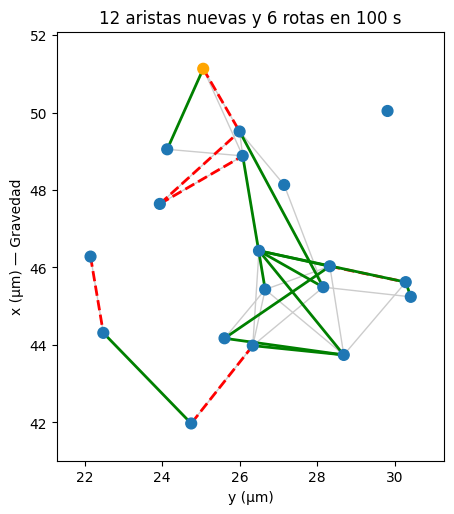

In [18]:
centro = ventana(X, x=(44, 48), y=(25, 29), z=(8, 12))[0]
vecindario = list(nx.single_source_shortest_path_length(G, centro, cutoff=2))
vecindario = [u for u in vecindario if presentes[u]]
H = G.subgraph(vecindario)
nuevas = [(u, v) for u in vecindario for v in vecindario if u < v and (u, v) in futuras and not G.has_edge(u, v)]
rotas = [(u, v) for u, v in H.edges() if tuple(sorted((u, v))) not in futuras]

plt.figure(figsize=(5, 6))

# Invertimos las coordenadas a [1, 0] (y horizontal, x vertical)
pos = {u: X[u, [1, 0]] for u in vecindario}

nx.draw_networkx_edges(H, pos, edge_color="0.8")
nx.draw_networkx_edges(H, pos, edgelist=rotas, edge_color="red", width=2, style="dashed")
nx.draw_networkx_edges(nx.Graph(nuevas), pos, edge_color="green", width=2)
nx.draw_networkx_nodes(H, pos, node_size=60, node_color=["orange" if u == centro else "tab:blue" for u in vecindario])

plt.title(f"{len(nuevas)} aristas nuevas y {len(rotas)} rotas en {25 * dt} s")
plt.gca().set_aspect("equal")
plt.xlabel("y (µm)")
plt.ylabel("x (µm) — Gravedad")
plt.gca().tick_params(left=True, bottom=True, labelleft=True, labelbottom=True)
plt.show()

**Discutan:** ¿En qué zona se forman más enlaces nuevos y por qué? ¿Por qué el AUC no se ve afectado por que los positivos sean tan pocos? La distancia predice mejor que los vecinos comunes: ¿Qué dice eso sobre la información que el grafo descarta?

## Respuestas

**¿En qué zona se forman más enlaces nuevos y por qué?**

La mayor proporción de enlaces nuevos se presenta en la zona del líquido, con un $10.5 \%$ de parejas positivas, seguida de la interfaz con un $4.0 \%$ y finalmente el cristal con apenas un $0.8 \%$.

Esto se explica por el comportamiento físico de las partículas en cada fase. En el líquido, las partículas tienen mayor movilidad debido al movimiento browniano, lo que facilita que cambien sus posiciones y establezcan nuevas conexiones con otras partículas. En cambio, en el cristal las partículas mantienen una estructura más ordenada y estable, por lo que sus vecinos cambian con menor frecuencia. La interfaz presenta un comportamiento intermedio.

**¿Por qué el AUC no se ve afectado por que los positivos sean tan pocos?**


El AUC no se ve afectado directamente por el hecho de que haya pocos positivos porque esta métrica evalúa la capacidad del modelo para distinguir y ordenar correctamente las parejas que forman nuevos enlaces frente a las que no los forman, independientemente de la proporción de cada clase.

En otras palabras, el AUC mide la probabilidad de que una pareja que forma un nuevo enlace reciba una puntuación de predicción mayor que una pareja que no forma un enlace.

Por ejemplo, en la zona cristalina solamente el 0.8 % de las parejas son positivas, pero se obtiene un AUC de 0.963 utilizando la distancia. Esto indica que, aunque los nuevos enlaces son poco frecuentes, la distancia permite identificarlos y diferenciarlos bastante bien de las parejas que no forman nuevos enlaces.



**La distancia predice mejor que los vecinos comunes: ¿Qué dice eso sobre la información que el grafo descarta?**

La distancia presenta una mejor capacidad predictiva porque proporciona información geométrica directa sobre la separación entre dos partículas. Las partículas que se encuentran más cerca tienen mayor probabilidad de convertirse en vecinas, ya que necesitan desplazarse menos para alcanzar el radio de conexión establecido.

Por otro lado, el número de vecinos comunes proporciona información sobre la conectividad de la red, pero no indica qué tan separadas están realmente las partículas. En otras palabras, el grafo de vecinos representa las relaciones entre partículas mediante nodos y aristas, pero pierde parte de la información geométrica del sistema.

En particular, no conserva directamente:

- Distancias exactas: solamente indica si dos partículas están conectadas o no según el radio de corte.
- Posiciones espaciales: no conserva las coordenadas tridimensionales originales de cada partícula.
- Direcciones de los enlaces: no indica hacia qué dirección se encuentra cada vecino.
- Orientación estructural: no representa directamente los ángulos ni la orientación de los enlaces entre partículas.


Esta información podría ser útil para mejorar las predicciones porque permite conocer la configuración espacial real de las partículas y estimar qué tan probable es que dos de ellas se aproximen lo suficiente para formar una nueva conexión.



## Tarea 5 (opcional). Enlaces que se rompen
La pregunta inversa: de las aristas en $t=0$ entre partículas presentes en $t+\Delta t$, ¿cuáles se romperán? Calcule la fracción de aristas rotas en el cristal y en el líquido, y el AUC de dos puntajes: menos vecinos comunes (un enlace con muchos vecinos comunes está "protegido" por su entorno) y la longitud del enlace.

In [19]:
# COMPLETAR (opcional): aristas de G entre partículas presentes, etiqueta "se rompe" y los dos AUC


# Parte C — Clasificación de grafos: ¿dónde termina el cristal?

Ahora cada capa de la muestra, de un diámetro de ancho a lo largo de $x$, en cada instante, es un grafo que hay que clasificar como cristal o líquido: 23 capas por 150 instantes dan 3450 grafos. Es la versión experimental de las fases del modelo de Ising, con la fracción de volumen en lugar de la temperatura.

Para cada capa calculamos cinco rasgos. Los tres últimos imitan los dominios del Ising: llamamos densa a una partícula con al menos 10 vecinos y estudiamos los grupos conectados que forman las partículas densas de la capa.

| rasgo | definición |
|---|---|
| grado medio | promedio de $d_u$ en la capa |
| agrupamiento medio | promedio de $c_u$ en la capa |
| fracción densa | fracción de partículas de la capa con $d_u\ge10$ |
| grupo mayor | tamaño del mayor grupo conectado de partículas densas, dividido por el número de partículas de la capa |
| número de grupos | número de grupos conectados de partículas densas = multiplicidad del autovalor 0 de su Laplaciano |

## Tarea 6. Rasgos de una capa
Complete `rasgos_de_capa`. Recibe el grafo del instante, el grado y el agrupamiento de cada nodo (ya calculados) y los nodos de la capa.



In [20]:
nombres_capa = ["grado medio", "agrupamiento", "fracción densa", "grupo mayor", "número de grupos"]


def rasgos_de_capa(G, grado, agrupamiento, nodos, umbral=10):

    """Cinco rasgos de la capa formada por `nodos` (arreglo de índices): grado medio,
    agrupamiento medio, fracción de partículas densas (grado >= umbral), tamaño relativo
    del mayor grupo conectado de partículas densas y número de esos grupos."""

    nodos = np.asarray(nodos)

    # Características promedio

    grado_medio = grado[nodos].mean()

    agrupamiento_medio = agrupamiento[nodos].mean()

    # Identificar partículas densas
    densos = [u for u in nodos if grado[u] >= umbral]

    # Fracción densa

    fraccion_densa = len(densos) / len(nodos)

    # Componentes conectadas

    grupos = list(nx.connected_components(G.subgraph(densos)))

    # Tamaño del grupo más grande

    grupo_mayor = (max(map(len, grupos)) / len(nodos) if grupos else 0)

    # Número de grupos
    numero_grupos = len(grupos)

    return np.array([grado_medio, agrupamiento_medio, fraccion_densa, grupo_mayor, numero_grupos])



In [21]:
# Verificación de la tarea 6

bordes = np.arange(0, 58.6, d)               # capas de un diámetro de ancho

centros = (bordes[:-1] + bordes[1:]) / 2

capa = np.digitize(X[:, 0], bordes) - 1

nodos = np.where(capa == 18)[0]              # una capa del lado líquido

r = rasgos_de_capa(G, grado, F[:, 1], nodos)

assert len(r) == 5 and np.isclose(r[0], grado[nodos].mean()) and np.isclose(r[1], F[nodos, 1].mean())

densos = [u for u in nodos if grado[u] >= 10]

ceros = np.sum(np.abs(np.linalg.eigvalsh(nx.laplacian_matrix(G.subgraph(densos)).toarray())) < 1e-8)

assert r[4] == ceros, "El número de grupos debe ser la multiplicidad del autovalor 0 del Laplaciano"
print("Tarea 6 correcta:", {n: round(float(v), 3) for n, v in zip(nombres_capa, r)})

Tarea 6 correcta: {'grado medio': 8.163, 'agrupamiento': 0.358, 'fracción densa': 0.262, 'grupo mayor': 0.064, 'número de grupos': 14.0}


### Ver dos capas
Una capa del cristal y una del líquido, vistas de frente (plano $y$–$z$). Las partículas densas están coloreadas según el grupo conectado al que pertenecen; las demás, en gris. En el cristal casi todas forman un único grupo; en el líquido aparecen muchos grupos pequeños.

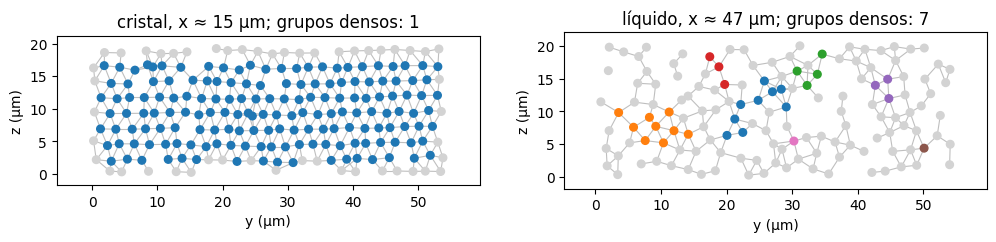

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for a, j, titulo in [(ax[0], 6, "cristal"), (ax[1], 20, "líquido")]:

    nodos = np.where(capa == j)[0]

    grupos = sorted(nx.connected_components(G.subgraph([u for u in nodos if grado[u] >= 10])), key=len, reverse=True)
    etiqueta = {u: g for g, grupo in enumerate(grupos) for u in grupo}

    colores = [plt.cm.tab10(etiqueta[u] % 10) if u in etiqueta else "lightgray" for u in nodos]
    dibujar(G, X, nodos, colores=colores, ejes=(1, 2), ax=a, node_size=30)
    a.set_title(f"{titulo}, x ≈ {centros[j]:.0f} µm; grupos densos: {len(grupos)}")
plt.show()

### La tabla de grafos
La celda siguiente recorre los 150 instantes y todas las capas, salvo la primera y la última, afectadas por el borde de la imagen. Para cada grafo guarda el instante, la posición de la capa, los cinco rasgos y la fracción de partículas con $N_o>7$, que **no** se usa para entrenar. Tarda menos de un minuto.

In [23]:
filas = []
for k in range(150):
    Xk, N_ok, _, _ = instante(k)
    Gk = grafo_de_vecinos(Xk, rc)
    grado_k = np.array([Gk.degree(u) for u in range(len(Xk))])

    # Calcular clustering y pasarlo a arreglo alineado con las partículas
    agrup_k = nx.clustering(Gk)
    agrup_k = np.array([agrup_k[u] for u in range(len(Xk))])

    capa_k = np.digitize(Xk[:, 0], bordes) - 1

    for j in range(1, len(centros) - 1):
        nodos = np.where(capa_k == j)[0]
        filas.append(
            [k, centros[j]] + list(rasgos_de_capa(Gk, grado_k, agrup_k, nodos)) + [np.mean(N_ok[nodos] > 7)]
        )

tabla = np.array(filas)
instante_g, xc, R, f_orden = tabla[:, 0], tabla[:, 1], tabla[:, 2:7], tabla[:, 7]
print(len(tabla), "grafos con", R.shape[1], "rasgos")

3450 grafos con 5 rasgos


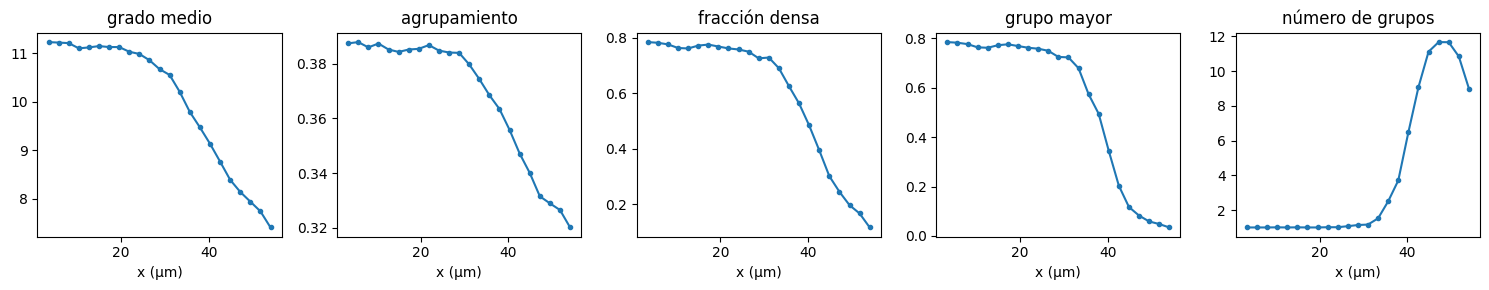

In [24]:
fig, ax = plt.subplots(1, 5, figsize=(15, 3))

for j in range(5):

    ax[j].plot(
        np.unique(xc),
        [
            R[xc == v, j].mean()
            for v in np.unique(xc)
        ],
        "o-",
        ms=3
    )

    ax[j].set_title(nombres_capa[j])
    ax[j].set_xlabel("x (µm)")

plt.tight_layout()
plt.show()

### Entrenar con los extremos, predecir el medio
Como en el modelo de Ising, entrenamos solo con los grafos de los que estamos seguros: las capas con $x<25$ µm son **cristal** (1) y las capas con $x>42$ µm son **líquido** (0). El modelo decide sobre las capas intermedias, y la interfaz es donde $P(\text{cristal})$ promediada en el tiempo cruza 0,5. La comparamos con la interfaz según el orden orientacional de los autores.

In [27]:
def cruce(x, f, nivel=0.5):
    """Primera posición donde f, que decrece con x, cruza el nivel (interpolación lineal)."""
    i = np.where(f < nivel)[0][0]
    return x[i - 1] + (nivel - f[i - 1]) * (x[i] - x[i - 1]) / (f[i] - f[i - 1])

entrena = (xc < 25) | (xc > 42)

modelo_capas = entrenar(R[entrena], (xc[entrena] < 30).astype(int))

p_cristal = modelo_capas.predict_proba(R)[:, 1]

xs = np.unique(xc)

P_media = np.array([p_cristal[xc == v].mean() for v in xs])

orden_media = np.array([f_orden[xc == v].mean() for v in xs])

x_grafo, x_orden = cruce(xs, P_media), cruce(xs, orden_media)

print(f"Exactitud en entrenamiento: {modelo_capas.score(R[entrena], (xc[entrena] < 30).astype(int)):.3f}")
print(f"Interfaz según el grafo:               x = {x_grafo:.1f} µm")
print(f"Interfaz según el orden orientacional: x = {x_orden:.1f} µm   (diferencia: {(x_grafo - x_orden) / d:.1f} d)")

Exactitud en entrenamiento: 1.000
Interfaz según el grafo:               x = 37.9 µm
Interfaz según el orden orientacional: x = 31.1 µm   (diferencia: 2.9 d)


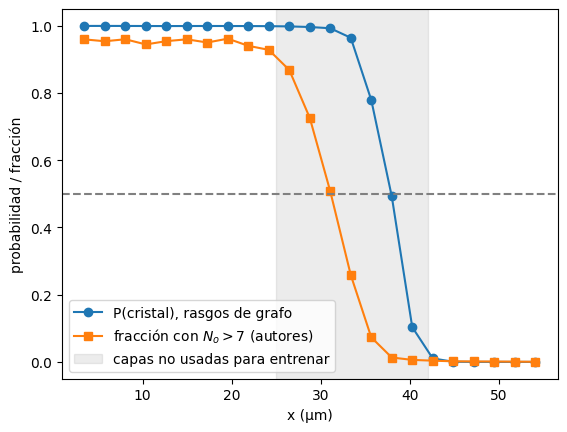

In [28]:
plt.plot(xs, P_media, "o-", label="P(cristal), rasgos de grafo")
plt.plot(xs, orden_media, "s-", label="fracción con $N_o>7$ (autores)")
plt.axvspan(25, 42, color="gray", alpha=0.15, label="capas no usadas para entrenar")
plt.axhline(0.5, ls="--", color="gray")
plt.xlabel("x (µm)"); plt.ylabel("probabilidad / fracción"); plt.legend()
plt.show()

**Discutan:** Las dos curvas cruzan 0,5 en lugares distintos. ¿Cuál describe mejor dónde termina el cristal? ¿Qué detecta el grafo cerca de la interfaz, orden o densidad? Pruebe a mover la ventana de entrenamiento del líquido ($x>36$ o $x>45$ µm): ¿qué pasa con la interfaz del grafo? Los autores encontraron algo parecido con sus propias medidas: el perfil de **densidad** a través de la interfaz es más ancho que el perfil de **orden** ($9{,}6\,d$ frente a $6{,}1\,d$ entre el 10 % y el 90 % del cambio). ¿Es coherente con lo que observa?

## Moviendo la ventana de entrenamiento

Pruebe a mover la ventana de entrenamiento del líquido ( $x>36$  o  $x>45$  µm): ¿qué pasa con la interfaz del grafo? Los autores encontraron algo parecido con sus propias medidas: el perfil de densidad a través de la interfaz es más ancho que el perfil de orden ( 9,6d  frente a  6,1d  entre el 10 % y el 90 % del cambio). ¿Es coherente con lo que observa?

In [29]:
entrena = (xc < 25) | (xc > 36)
modelo_capas = entrenar(R[entrena], (xc[entrena] < 30).astype(int))
p_cristal = modelo_capas.predict_proba(R)[:, 1]

xs = np.unique(xc)
P_media = np.array([p_cristal[xc == v].mean() for v in xs])
orden_media = np.array([f_orden[xc == v].mean() for v in xs])
x_grafo, x_orden = cruce(xs, P_media), cruce(xs, orden_media)
print(f"Ventana líquido: x > 36 | Interfaz grafo: x = {x_grafo:.1f} µm | Interfaz orden: x = {x_orden:.1f} µm")

Ventana líquido: x > 36 | Interfaz grafo: x = 34.2 µm | Interfaz orden: x = 31.1 µm


In [30]:
entrena = (xc < 25) | (xc > 45)
modelo_capas = entrenar(R[entrena], (xc[entrena] < 30).astype(int))
p_cristal = modelo_capas.predict_proba(R)[:, 1]

xs = np.unique(xc)
P_media = np.array([p_cristal[xc == v].mean() for v in xs])
orden_media = np.array([f_orden[xc == v].mean() for v in xs])
x_grafo, x_orden = cruce(xs, P_media), cruce(xs, orden_media)
print(f"Ventana líquido: x > 45 | Interfaz grafo: x = {x_grafo:.1f} µm | Interfaz orden: x = {x_orden:.1f} µm")

Ventana líquido: x > 45 | Interfaz grafo: x = 39.7 µm | Interfaz orden: x = 31.1 µm


Al modificar el umbral de entrenamiento del líquido, la interfaz predicha por el grafo se desplaza considerablemente, mientras que la interfaz real de orden permanece fija en $x = 31{,}1\,\mu\text{m}$:

- Con la ventana en $x > 36\,\mu\text{m}$, la interfaz del grafo baja a $x = 34{,}2\,\mu\text{m}$ (acercándose a la frontera de orden). Esto ocurre porque se incluyen capas de líquido denso dentro de la clase negativa, obligando al clasificador a exigir un mayor empaquetamiento para considerar una capa como cristal.

- Con la ventana en $x > 45\,\mu\text{m}$, la interfaz sube hasta $x = 39{,}7\,\mu\text{m}$. Al entrenar únicamente con el líquido más diluido de la zona superior, el modelo clasifica como "cristal" toda la franja intermedia donde las partículas siguen muy empaquetadas aunque ya hayan perdido su estructura cristalina.


Esto es coherente con el hallazgo de los autores. El hecho de que la posición de la frontera del grafo sea tan sensible a dónde se recorta el líquido ($34{,}2\,\mu\text{m}$ frente a $39{,}7\,\mu\text{m}$) demuestra que existe una zona de transición ancha entre $x \approx 31\,\mu\text{m}$ y $x \approx 45\,\mu\text{m}$ donde el orden orientacional ya cayó abruptamente (en una franja estrecha de $6{,}1\,d$), pero la densidad de vecinos sigue disminuyendo de forma muy gradual a lo largo de $9{,}6\,d$. Como los rasgos topológicos del grafo capturan principalmente el empaquetamiento local, su umbral de clasificación termina siguiendo este perfil ancho de densidad.

## Respuestas

**Las dos curvas cruzan $0.5$ en lugares distintos. ¿Cuál describe mejor dónde termina el cristal?**

La curva de los autores (fracción con $N_o > 7$) describe mejor dónde termina realmente el cristal porque un cristal se define físicamente por su orden orientacional. El parámetro $N_o$ mide directamente esa alineación angular mediante los armónicos esféricos $\hat{q}_{6m}$, marcando exactamente dónde se pierde la estructura cristalina.

**¿Qué detecta el grafo cerca de la interfaz, orden o densidad?**

El grafo detecta principalmente densidad, no orden orientacional porque  los rasgos de la capa (grado medio, fracción densa con $d_u \ge 10$, tamaño de componentes conectadas) dependen únicamente de cuántos vecinos hay dentro del radio de corte $r_c$. Como el grafo descarta las direcciones espaciales de los enlaces, un líquido muy comprimido cerca de la frontera tiene un empaquetamiento alto que el modelo confunde con cristal.




# Para la exposición (un equipo aleatoriamente presentará una parte)

Todos los equipos resuelven las tres partes. Para la exposición, prepare una tabla o figura de cada parte (A,B,C), presente las respuestas de la discusión y adicional responda:

- **Parte A.** ¿Cuánto mejora la agregación y por qué? ¿Dónde se equivoca el modelo?
- **Parte B.** ¿En qué zona cambian más los vecinos? ¿Por qué la distancia predice mejor que los vecinos comunes?
- **Parte C.** ¿Por qué la interfaz del grafo no coincide con la del orden orientacional, y cómo depende de la ventana de entrenamiento?

¿qué información de la muestra no captura el grafo de vecinos, y qué habría que añadirle para distinguir un cristal de un líquido denso?

# Uso declarado de la IA
Se utilizó Gemini (Google) como herramienta de apoyo conceptual y técnico para: (1) comprender el funcionamiento interno de métodos específicos de las librerías utilizadas (como el formato disperso .tocoo() de SciPy, el filtrado booleano con G.has_edge(), el cálculo de connected_components en NetworkX y la métrica roc_auc_score de Scikit-Learn), (2) ajustar la orientación de los ejes en la visualización del vecindario local de la Parte B, y (3) contrastar la interpretación física de los resultados en las preguntas de discusión. Verifiqué que era correcto porque lo contrasté cada parte del codigo con mi intuición y mis conocimientos.

*Escriba aquí su declaración.*

**Datos:** J. Hernández-Guzmán y E. R. Weeks, «The equilibrium intrinsic crystal–liquid interface of colloids», *Proc. Natl. Acad. Sci. USA* **106**(36), 15198–15202 (2009), [doi:10.1073/pnas.0904682106](https://doi.org/10.1073/pnas.0904682106). Datos publicados por el grupo de E. R. Weeks (Emory University).